In [187]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from pathlib import Path
import json

In [188]:
import json
from collections import Counter
from statistics import mean, median


CATEGORY_ALIASES = {
    "stable_s": "Stable Survived",
    "s": "Stable Survived",
    "stable_k": "Stable Killed",
    "k": "Stable Killed",
    "s->k": "Survived-to-Killed",
    "s_to_k": "Survived-to-Killed",
    "k->s": "Killed-to-Survived",
    "k_to_s": "Killed-to-Survived",
    "sks": "Survived-Killed-Survived",
    "s->k->s": "Survived-Killed-Survived",
    "ksk": "Killed-Survived-Killed",
    "k->s->k": "Killed-Survived-Killed",
    "recurrent": "Recurrent",
}


In [ ]:
def normalize_category(category):
    c = category.strip().lower().replace("→", "->")
    if c in CATEGORY_ALIASES:
        return CATEGORY_ALIASES[c]
    raise ValueError(f"Unknown category: {category}")


def collapse_statuses(statuses):
    collapsed = []
    for s in statuses:
        if not collapsed or collapsed[-1] != s:
            collapsed.append(s)
    return collapsed


def classify(collapsed):
    x = tuple(collapsed)

    if x == ("S",):
        return "Stable Survived"
    if x == ("K",):
        return "Stable Killed"
    if x == ("S", "K"):
        return "Survived-to-Killed"
    if x == ("K", "S"):
        return "Killed-to-Survived"
    if x == ("S", "K", "S"):
        return "Survived-Killed-Survived"
    if x == ("K", "S", "K"):
        return "Killed-Survived-Killed"
    if len(x) - 1 >= 3:
        return "Recurrent"

    return "Unclassifiable"


def get_sequence(record):
    seq = record.get("sequence", [])
    seq = [x for x in seq if x.get("status") in {"S", "K"}]

    if all("index" in x for x in seq):
        seq = sorted(seq, key=lambda x: x["index"])

    return seq


def fallback_stable_sequence(record):
    """
    Some stable mutants may not have `sequence`.
    This fallback reconstructs only stable S or stable K cases from counters.
    It cannot reconstruct real transition order.
    """
    s_to_k = record.get("S_to_K", 0)
    k_to_s = record.get("K_to_S", 0)
    s_to_s = record.get("S_to_S", 0)
    k_to_k = record.get("K_to_K", 0)

    if s_to_k == 0 and k_to_s == 0:
        if s_to_s > 0 and k_to_k == 0:
            return [{"index": i, "status": "S"} for i in range(s_to_s + 1)]
        if k_to_k > 0 and s_to_s == 0:
            return [{"index": i, "status": "K"} for i in range(k_to_k + 1)]

    return []


def compute_runs(seq):
    """
    Returns consecutive same-status runs.

    Example:
      S S S K K S
    becomes:
      S-run length 3, K-run length 2, S-run length 1
    """
    if not seq:
        return []

    runs = []
    start = 0

    for i in range(1, len(seq) + 1):
        if i == len(seq) or seq[i]["status"] != seq[start]["status"]:
            start_index = seq[start].get("index")
            end_index = seq[i - 1].get("index")

            index_span = None
            if isinstance(start_index, int) and isinstance(end_index, int):
                index_span = end_index - start_index + 1

            runs.append({
                "status": seq[start]["status"],
                "start_pos": start,
                "end_pos": i - 1,
                "observed_commits": i - start,
                "start_index": start_index,
                "end_index": end_index,
                "index_span": index_span,
            })

            start = i

    return runs


def safe_div(x, y):
    if x is None or y in (None, 0):
        return None
    return x / y


def analyze_mutant(mutant_key, record, allow_stable_fallback=True):
    seq = get_sequence(record)

    if not seq and allow_stable_fallback:
        seq = fallback_stable_sequence(record)

    if not seq:
        return None

    statuses = [x["status"] for x in seq]
    collapsed = collapse_statuses(statuses)
    category = classify(collapsed)
    runs = compute_runs(seq)

    transition_counts = Counter()
    transition_positions = []
    transition_indices = []

    for i in range(1, len(seq)):
        prev_s = seq[i - 1]["status"]
        cur_s = seq[i]["status"]

        if prev_s != cur_s:
            transition_counts[f"{prev_s}_to_{cur_s}"] += 1
            transition_positions.append(i)
            transition_indices.append(seq[i].get("index"))

    first_index = seq[0].get("index")
    last_index = seq[-1].get("index")

    n_observed_commits = len(seq)

    index_span_total = None
    if isinstance(first_index, int) and isinstance(last_index, int):
        index_span_total = last_index - first_index + 1

    # ------------------------------------------------------------
    # Transition timing
    # ------------------------------------------------------------
    time_to_first_transition_observed = None
    time_to_first_transition_index_span = None

    avg_time_between_transitions_observed = None
    avg_time_between_transitions_index_span = None

    relative_average_transition_position = None

    if transition_positions:
        # Number of observed S/K observations before the first status change.
        time_to_first_transition_observed = transition_positions[0]

        # Commit-index distance before the first status change.
        if isinstance(first_index, int) and isinstance(transition_indices[0], int):
            time_to_first_transition_index_span = transition_indices[0] - first_index

        # For recurrent patterns:
        # average relative position of all transitions.
        if category == "Recurrent":
            relative_average_transition_position = safe_div(
                sum(transition_positions) / len(transition_positions),
                n_observed_commits,
            )

    if len(transition_positions) >= 2:
        observed_intervals = [
            transition_positions[i] - transition_positions[i - 1]
            for i in range(1, len(transition_positions))
        ]

        avg_time_between_transitions_observed = (
            sum(observed_intervals) / len(observed_intervals)
        )

    if (
        len(transition_indices) >= 2
        and all(isinstance(x, int) for x in transition_indices)
    ):
        index_intervals = [
            transition_indices[i] - transition_indices[i - 1]
            for i in range(1, len(transition_indices))
        ]

        avg_time_between_transitions_index_span = (
            sum(index_intervals) / len(index_intervals)
        )

    killed_runs = [r for r in runs if r["status"] == "K"]
    survived_runs = [r for r in runs if r["status"] == "S"]

    # ------------------------------------------------------------
    # Relative position for temporal-position plot/table
    # ------------------------------------------------------------
    #
    # S -> K:
    #   relative first transition position
    #
    # K -> S:
    #   relative first transition position
    #
    # S -> K -> S:
    #   relative midpoint of the middle K-run
    #
    # K -> S -> K:
    #   relative midpoint of the middle S-run
    #
    # Recurrent:
    #   handled separately by relative_average_transition_position
    #
    relative_transition_or_run_position = None
    transition_or_run_position_kind = None

    # ------------------------------------------------------------
    # Relative duration of the middle run for double-transition cases
    # ------------------------------------------------------------
    #
    # S -> K -> S:
    #   relative duration of temporary K period
    #
    # K -> S -> K:
    #   relative duration of temporary S period
    #
    relative_middle_run_duration = None
    middle_run_duration_kind = None

    if category in {"Survived-to-Killed", "Killed-to-Survived"}:
        relative_transition_or_run_position = safe_div(
            time_to_first_transition_observed,
            n_observed_commits,
        )
        transition_or_run_position_kind = "relative_first_transition"

    elif category in {
        "Survived-Killed-Survived",
        "Killed-Survived-Killed",
    }:
        if len(runs) == 3:
            middle_run = runs[1]

            # Position: relative midpoint of the middle run.
            middle_run_midpoint_observed = (
                middle_run["start_pos"] + middle_run["end_pos"] + 1
            ) / 2

            relative_transition_or_run_position = safe_div(
                middle_run_midpoint_observed,
                n_observed_commits,
            )

            # Duration: relative length of the middle run.
            relative_middle_run_duration = safe_div(
                middle_run["observed_commits"],
                n_observed_commits,
            )

            if category == "Survived-Killed-Survived":
                transition_or_run_position_kind = "relative_middle_K_run_midpoint"
                middle_run_duration_kind = "relative_middle_K_run_duration"
            else:
                transition_or_run_position_kind = "relative_middle_S_run_midpoint"
                middle_run_duration_kind = "relative_middle_S_run_duration"

    return {
        "mutant_key": mutant_key,
        "category": category,
        "collapsed_sequence": "->".join(collapsed),

        "n_observed_commits": n_observed_commits,
        "index_span_total": index_span_total,

        "n_transitions": sum(transition_counts.values()),
        "transition_counts": dict(transition_counts),

        "run_lengths_observed": [r["observed_commits"] for r in runs],
        "run_lengths_index_span": [r["index_span"] for r in runs],

        "survived_run_lengths_observed": [r["observed_commits"] for r in survived_runs],
        "survived_run_lengths_index_span": [r["index_span"] for r in survived_runs],

        "killed_run_lengths_observed": [r["observed_commits"] for r in killed_runs],
        "killed_run_lengths_index_span": [r["index_span"] for r in killed_runs],

        "time_to_first_transition_observed": time_to_first_transition_observed,
        "time_to_first_transition_index_span": time_to_first_transition_index_span,

        "avg_time_between_transitions_observed": avg_time_between_transitions_observed,
        "avg_time_between_transitions_index_span": avg_time_between_transitions_index_span,

        # For S->K, K->S, SKS, KSK temporal-position plot/table.
        "relative_transition_or_run_position": relative_transition_or_run_position,
        "transition_or_run_position_kind": transition_or_run_position_kind,

        # For recurrent temporal-position plot.
        "relative_average_transition_position": relative_average_transition_position,

        # For SKS/KSK duration plot/table.
        "relative_middle_run_duration": relative_middle_run_duration,
        "middle_run_duration_kind": middle_run_duration_kind,
    }    

def summarize(values):
    values = [v for v in values if v is not None]

    if not values:
        return {
            "n": 0,
            "mean": None,
            "median": None,
            "min": None,
            "max": None,
        }

    return {
        "n": len(values),
        "mean": mean(values),
        "median": median(values),
        "min": min(values),
        "max": max(values),
    }


def flatten(list_of_lists):
    return [x for xs in list_of_lists for x in xs]


def summarize_metrics(metrics):
    transition_counts = Counter()

    for m in metrics:
        transition_counts.update(m["transition_counts"])

    return {
        "n_mutants": len(metrics),

        "transition_counts": dict(transition_counts),

        "n_transitions_per_mutant": summarize(
            [m["n_transitions"] for m in metrics]
        ),

        "observed_commits_per_mutant": summarize(
            [m["n_observed_commits"] for m in metrics]
        ),

        "index_span_per_mutant": summarize(
            [m["index_span_total"] for m in metrics]
        ),

        "time_to_first_transition_observed": summarize(
            [m["time_to_first_transition_observed"] for m in metrics]
        ),

        "time_to_first_transition_index_span": summarize(
            [m["time_to_first_transition_index_span"] for m in metrics]
        ),

        "survived_run_lengths_observed": summarize(
            flatten([m["survived_run_lengths_observed"] for m in metrics])
        ),

        "survived_run_lengths_index_span": summarize(
            flatten([m["survived_run_lengths_index_span"] for m in metrics])
        ),

        "killed_run_lengths_observed": summarize(
            flatten([m["killed_run_lengths_observed"] for m in metrics])
        ),

        "killed_run_lengths_index_span": summarize(
            flatten([m["killed_run_lengths_index_span"] for m in metrics])
        ),
    }


def analyze_file(json_path, category=None):
    with open(json_path, "r", encoding="utf-8") as f:
        data = json.load(f)

    target_category = normalize_category(category) if category else None

    per_mutant = []

    for mutant_key, record in data.items():
        result = analyze_mutant(mutant_key, record)

        if result is None:
            continue

        if target_category is None or result["category"] == target_category:
            per_mutant.append(result)

    return {
        "requested_category": target_category or "ALL",
        "summary": summarize_metrics(per_mutant),
        "per_mutant": per_mutant,
    }

In [103]:
json_file = "data_seq/black-13b_rq1.json"
result = analyze_file(json_file, category="s->k")

#output = json.dumps(result, indent=2)

In [8]:
type(result['per_mutant'])

list

In [9]:
result['per_mutant'][0]

{'mutant_key': 'black.py#0',
 'category': 'Stable Killed',
 'collapsed_sequence': 'K',
 'n_observed_commits': 100,
 'index_span_total': 100,
 'n_transitions': 0,
 'transition_counts': {},
 'run_lengths_observed': [100],
 'run_lengths_index_span': [100],
 'survived_run_lengths_observed': [],
 'survived_run_lengths_index_span': [],
 'killed_run_lengths_observed': [100],
 'killed_run_lengths_index_span': [100],
 'time_to_first_transition_observed': None,
 'time_to_first_transition_index_span': None,
 'relative_transition_or_run_position': None,
 'transition_or_run_position_kind': None}

In [ ]:
result['per_mutant'][1], result['requested_category']

In [50]:
r = None
for v in result['per_mutant']:
    if v['mutant_key']  == "black.py#145":
        r = v
        break 

In [130]:
import math
import statistics


PATTERN_ORDER = [
    "Stable Survived",
    "Stable Killed",
    "Survived-to-Killed",
    "Killed-to-Survived",
    "Survived-Killed-Survived",
    "Killed-Survived-Killed",
    "Recurrent",
]

PATTERN_LATEX = {
    "Stable Survived": r"Stable \(S\)",
    "Stable Killed": r"Stable \(K\)",
    "Survived-to-Killed": r"\(S \rightarrow K\)",
    "Killed-to-Survived": r"\(K \rightarrow S\)",
    "Survived-Killed-Survived": r"\(S \rightarrow K \rightarrow S\)",
    "Killed-Survived-Killed": r"\(K \rightarrow S \rightarrow K\)",
    "Recurrent": r"Recurrent",
}


def percentile(values, p):
    """
    Linear-interpolated percentile.
    p should be between 0 and 100.
    """
    values = sorted(v for v in values if v is not None)

    if not values:
        return None

    if len(values) == 1:
        return values[0]

    k = (len(values) - 1) * (p / 100)
    f = math.floor(k)
    c = math.ceil(k)

    if f == c:
        return values[int(k)]

    return values[f] * (c - k) + values[c] * (k - f)


def median_iqr(values):
    values = [v for v in values if v is not None]

    if not values:
        return None

    med = statistics.median(values)
    q1 = percentile(values, 25)
    q3 = percentile(values, 75)

    return med, q1, q3


def format_median_iqr(values, digits=2):
    stats = median_iqr(values)

    if stats is None:
        return "--"

    med, q1, q3 = stats

    return f"{med:.{digits}f} [{q1:.{digits}f}, {q3:.{digits}f}]"


def analyze_directory(data_dir, project=None, exclude_or_include=0):
    """
    Read all JSON files under data_dir and analyze every mutant.
    """
    data_dir = Path(data_dir)

    all_mutants = []

    for json_path in sorted(data_dir.glob("*.json")):
        ##
        if project is not None:
            if exclude_or_include == 1 and project not in json_path.name: # exclude_or_include=1 means include only the specified project
                continue
            elif exclude_or_include == 0 and project in json_path.name: #exclude_or_include=0 means exclude the specified project
                continue
        ##
        with open(json_path, "r", encoding="utf-8") as f:
            data = json.load(f)

        for mutant_key, record in data.items():
            result = analyze_mutant(mutant_key, record)

            if result is None:
                continue

            result["source_file"] = str(json_path)
            all_mutants.append(result)

    return all_mutants


def group_by_category(mutants):
    grouped = {cat: [] for cat in PATTERN_ORDER}

    for m in mutants:
        cat = m["category"]
        if cat in grouped:
            grouped[cat].append(m)

    return grouped


def make_temporal_table_rows(mutants):
    grouped = group_by_category(mutants)

    rows = []

    for cat in PATTERN_ORDER:
        ms = grouped[cat]

        n_observed_values = [
            m["n_observed_commits"]
            for m in ms
        ]

        n_observed_cell = format_median_iqr(
            n_observed_values,
            digits=0,
        )

        if cat in {
            "Stable Survived",
            "Stable Killed",
        }:
            temporal_cell = "--"

        elif cat in {
            "Survived-to-Killed",
            "Killed-to-Survived",
            "Survived-Killed-Survived",
            "Killed-Survived-Killed",
        }:
            temporal_values = [
                m["relative_transition_or_run_position"]
                for m in ms
            ]
            #if cat == "Survived-Killed-Survived":
            #    print (temporal_values)
            #    print ('==end==')
            #    return temporal_values
                
            temporal_cell = format_median_iqr(
                temporal_values,
                digits=2,
            )

        elif cat == "Recurrent":
            transition_values = [
                m["n_transitions"]
                for m in ms
            ]

            avg_transition_time_values = [
                m["avg_time_between_transitions_observed"]
                for m in ms
            ]

            n_trans_cell = format_median_iqr(
                transition_values,
                digits=0,
            )

            avg_time_cell = format_median_iqr(
                avg_transition_time_values,
                digits=2,
            )

            temporal_cell = f"{n_trans_cell}, {avg_time_cell}"

        else:
            temporal_cell = "--"

        rows.append((PATTERN_LATEX[cat], n_observed_cell, temporal_cell, len(ms)))

    return rows


def print_temporal_latex_table(mutants, include_n_comment=True):
    rows = make_temporal_table_rows(mutants)

    print(r"\begin{table}[t]")
    print(r"\centering")
    print(r"\caption{Temporal characteristics of longitudinal mutant-status patterns.}")
    print(r"\label{tab:rq1_temporal}")
    print(r"\begin{tabular}{lrr}")
    print(r"\toprule")
    print(r"\textbf{Pattern}")
    print(r"& \(\mathbf{n_{\mathrm{observed}}}\)")
    print(r"& \textbf{Transition/run position} \\")
    print(r"\midrule")

    for pattern, n_observed_cell, temporal_cell, n_mutants in rows:
        if include_n_comment:
            print(
                rf"{pattern} & {n_observed_cell} & {temporal_cell} \\ % n={n_mutants}"
            )
        else:
            print(
                rf"{pattern} & {n_observed_cell} & {temporal_cell} \\"
            )

    print(r"\bottomrule")
    print(r"\end{tabular}")
    print(r"\end{table}")

In [175]:
datadir = Path("data_seq")

mutants = analyze_directory(datadir, project = "black", exclude_or_include = 1) # include only black project
print_temporal_latex_table(mutants)

\begin{table}[t]
\centering
\caption{Temporal characteristics of longitudinal mutant-status patterns.}
\label{tab:rq1_temporal}
\begin{tabular}{lrr}
\toprule
\textbf{Pattern}
& \(\mathbf{n_{\mathrm{observed}}}\)
& \textbf{Transition/run position} \\
\midrule
Stable \(S\) & 83 [23, 100] & -- \\ % n=481
Stable \(K\) & 100 [49, 100] & -- \\ % n=24371
\(S \rightarrow K\) & 93 [53, 100] & 0.22 [0.05, 0.62] \\ % n=91
\(K \rightarrow S\) & 67 [50, 100] & 0.07 [0.05, 0.70] \\ % n=11
\(S \rightarrow K \rightarrow S\) & -- & -- \\ % n=0
\(K \rightarrow S \rightarrow K\) & 100 [97, 100] & 0.96 [0.47, 0.98] \\ % n=1273
Recurrent & 100 [57, 100] & 4 [3, 4], 4.33 [4.00, 16.00] \\ % n=120
\bottomrule
\end{tabular}
\end{table}


## Duration

In [195]:

DURATION_PATTERN_ORDER = [
    "Stable-Survived",
    "Stable-Killed",
    "Survived-to-Killed",
    "Killed-to-Survived",
    "Survived-Killed-Survived",
    "Killed-Survived-Killed",
    "Recurrent",
]

DURATION_PATTERN_LABELS = {
    "Stable-Survived": r"Stable \(S\)",
    "Stable-Killed": r"Stable \(K\)",
    "Survived-to-Killed": r"\(S \rightarrow K\)",
    "Killed-to-Survived": r"\(K \rightarrow S\)",
    "Survived-Killed-Survived": r"\(S \rightarrow K \rightarrow S\)",
    "Killed-Survived-Killed": r"\(K \rightarrow S \rightarrow K\)",
    "Recurrent": "Recurrent",
}

import math
from collections import defaultdict


def median_iqr(values):
    values = [v for v in values if v is not None]

    if not values:
        return None

    values = sorted(values)
    n = len(values)

    def percentile(p):
        if n == 1:
            return values[0]

        pos = (n - 1) * p
        lo = math.floor(pos)
        hi = math.ceil(pos)

        if lo == hi:
            return values[int(pos)]

        return values[lo] + (values[hi] - values[lo]) * (pos - lo)

    return {
        "median": percentile(0.50),
        "q1": percentile(0.25),
        "q3": percentile(0.75),
        "n": n,
    }


def format_median_iqr(values, digits=1):
    s = median_iqr(values)

    if s is None:
        return "--"

    if digits == 0:
        return (
            f"{s['median']:.0f} "
            f"[{s['q1']:.0f}, {s['q3']:.0f}]"
        )

    return (
        f"{s['median']:.{digits}f} "
        f"[{s['q1']:.{digits}f}, {s['q3']:.{digits}f}]"
    )
    
def get_run_lengths_by_position(m):
    """
    Absolute segment durations in number of valid observations.
    Example:
      S S K K K S
      returns [2, 3, 1]
    """
    return m.get("run_lengths_observed", [])


def get_relative_run_lengths_by_position(m):
    """
    Relative segment durations.

    Example:
      run_lengths_observed = [2, 3, 1]
      n_observed_commits = 6
      returns [0.333, 0.500, 0.167]
    """
    runs = m.get("run_lengths_observed", [])
    n = m.get("n_observed_commits")

    if not runs or not n:
        return []

    return [r / n for r in runs]


def format_abs_and_relative(abs_values, rel_values):
    """
    Format as:
      absolute median [IQR] (relative median% [IQR%])

    Example:
      2 [1, 4] (3.2\\% [1.1, 6.5])
    """
    abs_cell = format_median_iqr(abs_values, digits=0)

    rel_values_pct = [
        v * 100
        for v in rel_values
        if v is not None
    ]
    rel_cell = format_median_iqr(rel_values_pct, digits=1)

    if abs_cell == "--" and rel_cell == "--":
        return "--"

    if abs_cell == "--":
        return f"({rel_cell}\\%)"

    if rel_cell == "--":
        return abs_cell

    return f"{abs_cell} ({rel_cell}\\%)"


def make_duration_table_rows(mutants):
    grouped = defaultdict(list)

    for m in mutants:
        grouped[m["category"]].append(m)

    rows = []

    for cat in DURATION_PATTERN_ORDER:
        ms = grouped.get(cat, [])

        if not ms:
            rows.append((
                DURATION_PATTERN_LABELS[cat],
                "0",
                "--",
                "--",
                "--",
            ))
            continue

        # ------------------------------------------------------------
        # Stable S / Stable K
        # One segment: whole observed lifetime
        # ------------------------------------------------------------
        if cat in {"Stable-Survived", "Stable-Killed"}:
            total_duration_abs = [
                m["n_observed_commits"]
                for m in ms
            ]

            total_duration_rel = [
                1.0
                for _ in ms
            ]

            rows.append((
                DURATION_PATTERN_LABELS[cat],
                str(len(ms)),
                format_abs_and_relative(total_duration_abs, total_duration_rel),
                "--",
                "--",
            ))

        # ------------------------------------------------------------
        # S -> K
        # Segment 1: initial S duration
        # Segment 2: final K duration
        # ------------------------------------------------------------
        elif cat == "Survived-to-Killed":
            initial_s_abs = []
            final_k_abs = []

            initial_s_rel = []
            final_k_rel = []

            for m in ms:
                abs_runs = get_run_lengths_by_position(m)
                rel_runs = get_relative_run_lengths_by_position(m)

                if len(abs_runs) == 2 and len(rel_runs) == 2:
                    initial_s_abs.append(abs_runs[0])
                    final_k_abs.append(abs_runs[1])

                    initial_s_rel.append(rel_runs[0])
                    final_k_rel.append(rel_runs[1])

            rows.append((
                DURATION_PATTERN_LABELS[cat],
                str(len(ms)),
                format_abs_and_relative(initial_s_abs, initial_s_rel),
                format_abs_and_relative(final_k_abs, final_k_rel),
                "--",
            ))

        # ------------------------------------------------------------
        # K -> S
        # Segment 1: initial K duration
        # Segment 2: final S duration
        # ------------------------------------------------------------
        elif cat == "Killed-to-Survived":
            initial_k_abs = []
            final_s_abs = []

            initial_k_rel = []
            final_s_rel = []

            for m in ms:
                abs_runs = get_run_lengths_by_position(m)
                rel_runs = get_relative_run_lengths_by_position(m)

                if len(abs_runs) == 2 and len(rel_runs) == 2:
                    initial_k_abs.append(abs_runs[0])
                    final_s_abs.append(abs_runs[1])

                    initial_k_rel.append(rel_runs[0])
                    final_s_rel.append(rel_runs[1])

            rows.append((
                DURATION_PATTERN_LABELS[cat],
                str(len(ms)),
                format_abs_and_relative(initial_k_abs, initial_k_rel),
                format_abs_and_relative(final_s_abs, final_s_rel),
                "--",
            ))

        # ------------------------------------------------------------
        # S -> K -> S
        # Segment 1: initial S duration
        # Segment 2: temporary K duration
        # Segment 3: final S duration
        # ------------------------------------------------------------
        elif cat == "Survived-Killed-Survived":
            initial_s_abs = []
            temporary_k_abs = []
            final_s_abs = []

            initial_s_rel = []
            temporary_k_rel = []
            final_s_rel = []

            for m in ms:
                abs_runs = get_run_lengths_by_position(m)
                rel_runs = get_relative_run_lengths_by_position(m)

                if len(abs_runs) == 3 and len(rel_runs) == 3:
                    initial_s_abs.append(abs_runs[0])
                    temporary_k_abs.append(abs_runs[1])
                    final_s_abs.append(abs_runs[2])

                    initial_s_rel.append(rel_runs[0])
                    temporary_k_rel.append(rel_runs[1])
                    final_s_rel.append(rel_runs[2])

            rows.append((
                DURATION_PATTERN_LABELS[cat],
                str(len(ms)),
                format_abs_and_relative(initial_s_abs, initial_s_rel),
                format_abs_and_relative(temporary_k_abs, temporary_k_rel),
                format_abs_and_relative(final_s_abs, final_s_rel),
            ))

        # ------------------------------------------------------------
        # K -> S -> K
        # Segment 1: initial K duration
        # Segment 2: temporary S duration
        # Segment 3: final K duration
        # ------------------------------------------------------------
        elif cat == "Killed-Survived-Killed":
            initial_k_abs = []
            temporary_s_abs = []
            final_k_abs = []

            initial_k_rel = []
            temporary_s_rel = []
            final_k_rel = []

            for m in ms:
                abs_runs = get_run_lengths_by_position(m)
                rel_runs = get_relative_run_lengths_by_position(m)

                if len(abs_runs) == 3 and len(rel_runs) == 3:
                    initial_k_abs.append(abs_runs[0])
                    temporary_s_abs.append(abs_runs[1])
                    final_k_abs.append(abs_runs[2])

                    initial_k_rel.append(rel_runs[0])
                    temporary_s_rel.append(rel_runs[1])
                    final_k_rel.append(rel_runs[2])

            rows.append((
                DURATION_PATTERN_LABELS[cat],
                str(len(ms)),
                format_abs_and_relative(initial_k_abs, initial_k_rel),
                format_abs_and_relative(temporary_s_abs, temporary_s_rel),
                format_abs_and_relative(final_k_abs, final_k_rel),
            ))

        # ------------------------------------------------------------
        # Recurrent
        # Segment 1: all run durations
        # Segment 2: maximum run duration per mutant
        # Segment 3: --
        # ------------------------------------------------------------
        elif cat == "Recurrent":
            all_run_abs = []
            all_run_rel = []

            max_run_abs = []
            max_run_rel = []

            for m in ms:
                abs_runs = get_run_lengths_by_position(m)
                rel_runs = get_relative_run_lengths_by_position(m)

                if abs_runs and rel_runs:
                    all_run_abs.extend(abs_runs)
                    all_run_rel.extend(rel_runs)

                    max_run_abs.append(max(abs_runs))
                    max_run_rel.append(max(rel_runs))

            rows.append((
                DURATION_PATTERN_LABELS[cat],
                str(len(ms)),
                format_abs_and_relative(all_run_abs, all_run_rel),
                format_abs_and_relative(max_run_abs, max_run_rel),
                "--",
            ))

    return rows

def print_duration_latex_table(mutants):
    rows = make_duration_table_rows(mutants)

    print(r"""\begin{table}[t]
\centering
\caption{Duration of status segments in longitudinal mutant-status patterns. Each cell reports the median [IQR] segment duration in valid observations, followed by the corresponding relative duration in parentheses.}
\label{tab:rq1_duration}
\small
\begin{tabular}{lrrrr}
\toprule
\textbf{Pattern}
& \(\mathbf{n}\)
& \textbf{Segment 1}
& \textbf{Segment 2}
& \textbf{Segment 3} \\
\midrule""")

    for pattern, n, seg1, seg2, seg3 in rows:
        print(f"{pattern} & {n} & {seg1} & {seg2} & {seg3} \\\\")

    print(r"""\bottomrule
\end{tabular}
\end{table}""")

In [189]:
mutants = analyze_directory("data_seq")
print_duration_latex_table(mutants)

\begin{table}[t]
\centering
\caption{Duration of status segments in longitudinal mutant-status patterns. Each cell reports median [IQR] in the number of valid observations.}
\label{tab:rq1_duration}
\small
\begin{tabular}{lrrrr}
\toprule
\textbf{Pattern}
& \(\mathbf{n}\)
& \textbf{Segment 1}
& \textbf{Segment 2}
& \textbf{Segment 3} \\
\midrule
Stable \(S\) & 0 & -- & -- & -- \\
Stable \(K\) & 0 & -- & -- & -- \\
\(S \rightarrow K\) & 570 & 25.0 [4.0, 35.0] & 8.0 [1.0, 40.0] & -- \\
\(K \rightarrow S\) & 243 & 14.0 [2.0, 69.0] & 9.0 [1.0, 54.0] & -- \\
\(S \rightarrow K \rightarrow S\) & 946 & 71.0 [71.0, 71.0] & 1.0 [1.0, 1.0] & 28.0 [28.0, 28.0] \\
\(K \rightarrow S \rightarrow K\) & 1311 & 47.0 [47.0, 98.0] & 1.0 [1.0, 1.0] & 1.0 [1.0, 52.0] \\
Recurrent & 694 & 3.0 [1.0, 10.0] & 20.0 [16.0, 52.0] & -- \\
\bottomrule
\end{tabular}
\end{table}


In [196]:
mutants = analyze_directory("data_seq")
print_duration_latex_table(mutants)

\begin{table}[t]
\centering
\caption{Duration of status segments in longitudinal mutant-status patterns. Each cell reports the median [IQR] segment duration in valid observations, followed by the corresponding relative duration in parentheses.}
\label{tab:rq1_duration}
\small
\begin{tabular}{lrrrr}
\toprule
\textbf{Pattern}
& \(\mathbf{n}\)
& \textbf{Segment 1}
& \textbf{Segment 2}
& \textbf{Segment 3} \\
\midrule
Stable \(S\) & 0 & -- & -- & -- \\
Stable \(K\) & 0 & -- & -- & -- \\
\(S \rightarrow K\) & 570 & 25 [4, 35] (66.7 [32.0, 93.1]\%) & 8 [1, 40] (33.3 [6.9, 68.0]\%) & -- \\
\(K \rightarrow S\) & 243 & 14 [2, 69] (71.2 [6.1, 95.0]\%) & 9 [1, 54] (28.7 [5.0, 93.9]\%) & -- \\
\(S \rightarrow K \rightarrow S\) & 946 & 71 [71, 71] (71.0 [71.0, 71.0]\%) & 1 [1, 1] (1.0 [1.0, 1.0]\%) & 28 [28, 28] (28.0 [28.0, 28.0]\%) \\
\(K \rightarrow S \rightarrow K\) & 1311 & 47 [47, 98] (91.7 [47.0, 98.0]\%) & 1 [1, 1] (1.0 [1.0, 1.1]\%) & 1 [1, 52] (3.6 [1.0, 52.0]\%) \\
Recurrent & 694 & 3 [1

In [198]:
mutants = analyze_directory("data_seq", project = "youtube-dl", exclude_or_include = 1) # include only black project
print_duration_latex_table(mutants)

\begin{table}[t]
\centering
\caption{Duration of status segments in longitudinal mutant-status patterns. Each cell reports the median [IQR] segment duration in valid observations, followed by the corresponding relative duration in parentheses.}
\label{tab:rq1_duration}
\small
\begin{tabular}{lrrrr}
\toprule
\textbf{Pattern}
& \(\mathbf{n}\)
& \textbf{Segment 1}
& \textbf{Segment 2}
& \textbf{Segment 3} \\
\midrule
Stable \(S\) & 0 & -- & -- & -- \\
Stable \(K\) & 0 & -- & -- & -- \\
\(S \rightarrow K\) & 50 & 56 [49, 99] (90.3 [49.0, 99.0]\%) & 6 [1, 51] (9.7 [1.0, 51.0]\%) & -- \\
\(K \rightarrow S\) & 45 & 99 [99, 99] (99.0 [99.0, 99.0]\%) & 1 [1, 1] (1.0 [1.0, 1.0]\%) & -- \\
\(S \rightarrow K \rightarrow S\) & 742 & 71 [71, 71] (71.0 [71.0, 71.0]\%) & 1 [1, 1] (1.0 [1.0, 1.0]\%) & 28 [28, 28] (28.0 [28.0, 28.0]\%) \\
\(K \rightarrow S \rightarrow K\) & 0 & -- & -- & -- \\
Recurrent & 0 & -- & -- & -- \\
\bottomrule
\end{tabular}
\end{table}


In [178]:
vs = make_temporal_table_rows(mutants)

In [214]:
PLOT_PATTERN_ORDER = [
    "Survived-to-Killed",
    "Killed-to-Survived",
    "Survived-Killed-Survived",
    "Killed-Survived-Killed",
    "Recurrent",
]

PLOT_PATTERN_LABELS = {
    "Survived-to-Killed": r"$S \rightarrow K$",
    "Killed-to-Survived": r"$K \rightarrow S$",
    "Survived-Killed-Survived": r"$S \rightarrow K \rightarrow S$",
    "Killed-Survived-Killed": r"$K \rightarrow S \rightarrow K$",
    "Recurrent": "Recurrent",
}

PLOT_PATTERN_COLORS = {
    "Survived-to-Killed": "tab:blue",
    "Killed-to-Survived": "tab:orange",
    "Survived-Killed-Survived": "tab:green",
    "Killed-Survived-Killed": "tab:red",
    "Recurrent": "tab:purple",
}
    
def get_relative_temporal_position(m):
    """
    Returns the y-value for the temporal-position plot.

    For single-transition patterns:
      relative first-transition position.

    For double-transition patterns:
      relative midpoint of the middle run.

    For recurrent patterns:
      relative average position of all transitions.
    """
    if m["category"] == "Recurrent":
        return m.get("relative_average_transition_position")

    return m.get("relative_transition_or_run_position")


def plot_relative_temporal_position_ecdf(
    mutants,
    out_path="relative_temporal_position_ecdf.pdf",
):
    fig, ax = plt.subplots(figsize=(6.8, 3.6))


    for cat in PLOT_PATTERN_ORDER:
        values = [
            get_relative_temporal_position(m)
            for m in mutants
            if m["category"] == cat
        ]
        values = sorted(v for v in values if v is not None)

        if not values:
            continue

        y = [
            (i + 1) / len(values)
            for i in range(len(values))
        ]

        ax.step(
            values,
            y,
            where="post",
            label=PLOT_PATTERN_LABELS[cat],
            color=PLOT_PATTERN_COLORS[cat],
        )

    ax.set_xlabel("Relative temporal position", fontsize=13)
    ax.set_ylabel("Cumulative fraction of mutants", fontsize=12)
    ax.set_xlim(-0.02, 1.02)
    ax.set_ylim(0, 1.02)
    ax.tick_params(axis="both", which="major", labelsize=12)
    ax.grid(axis="both", linestyle="--", linewidth=0.5, alpha=0.5)
    ax.legend(frameon=False, fontsize=10)

    fig.tight_layout()
    fig.savefig(out_path, bbox_inches="tight")
    plt.show()
    plt.close(fig)

    print(f"Saved: {out_path}")

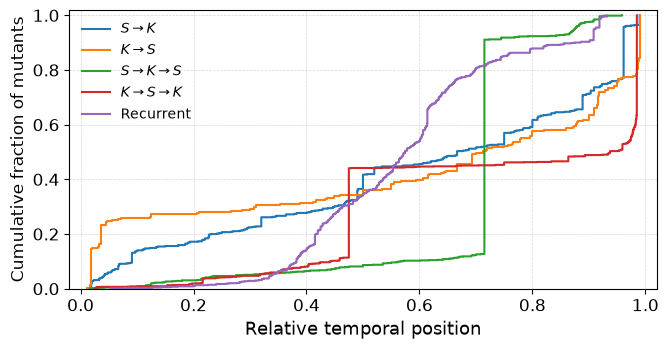

Saved: relative_temporal_position.pdf


In [215]:
mutants = analyze_directory("data_seq")
plot_relative_temporal_position_ecdf(
    mutants,
    out_path="relative_temporal_position.pdf",
)

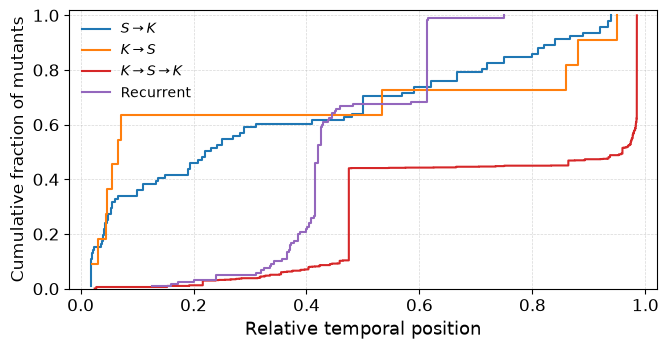

Saved: relative_temporal_position_black.pdf


In [218]:
mutants = analyze_directory("data_seq", project="black", exclude_or_include=1)
plot_relative_temporal_position_ecdf(
    mutants,
    out_path="relative_temporal_position_black.pdf",
)

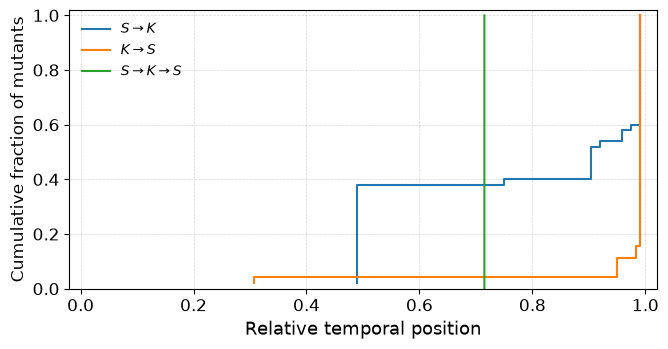

Saved: relative_temporal_position_youtube-dl.pdf


In [219]:
mutants = analyze_directory("data_seq", project="youtube-dl", exclude_or_include=1)
plot_relative_temporal_position_ecdf(
    mutants,
    out_path="relative_temporal_position_youtube-dl.pdf",
)

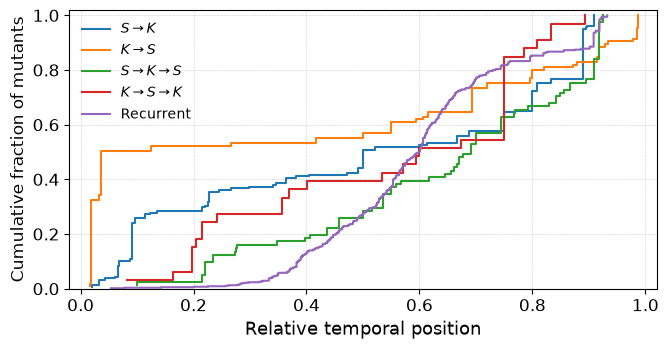

Saved: relative_temporal_position_tqdm.pdf


In [220]:
mutants = analyze_directory("data_seq", project="tqdm", exclude_or_include=1)
plot_relative_temporal_position_ecdf(
    mutants,
    out_path="relative_temporal_position_tqdm.pdf",
)

In [182]:
freq = Counter(m["category"] for m in mutants) 
print (freq)
print (len(mutants))

Counter({'Stable Survived': 2196, 'Stable Killed': 1863, 'Survived-Killed-Survived': 120, 'Survived-to-Killed': 103, 'Killed-to-Survived': 76, 'Recurrent': 14, 'Killed-Survived-Killed': 5})
4377


In [183]:
DOUBLE_PATTERN_ORDER = [
    "Survived-Killed-Survived",
    "Killed-Survived-Killed",
]

DOUBLE_PATTERN_LABELS = {
    "Survived-Killed-Survived": r"$S \rightarrow K \rightarrow S$",
    "Killed-Survived-Killed": r"$K \rightarrow S \rightarrow K$",
}


def plot_relative_middle_run_duration(
    mutants,
    out_path="relative_middle_run_duration.pdf",
):
    data = []
    labels = []

    for cat in DOUBLE_PATTERN_ORDER:
        all_cat = [
            m for m in mutants
            if m["category"] == cat
        ]

        values = [
            m.get("relative_middle_run_duration")
            for m in all_cat
        ]
        values = [v for v in values if v is not None]

        print(
            f"{cat}: total mutants={len(all_cat)}, "
            f"duration values={len(values)}"
        )

        if values:
            data.append(values)
            labels.append(DOUBLE_PATTERN_LABELS[cat])

    if not data:
        print("No data available for middle-run duration plot.")
        return

    fig, ax = plt.subplots(figsize=(4.8, 3.4))

    try:
        ax.boxplot(
            data,
            tick_labels=labels,
            showfliers=False,
            widths=0.5,
            patch_artist=False,
        )
    except TypeError:
        ax.boxplot(
            data,
            labels=labels,
            showfliers=False,
            widths=0.5,
            patch_artist=False,
        )

    ax.set_ylabel("Relative middle-run duration")
    ax.set_ylim(-0.02, 1.02)
    ax.set_xlabel("Longitudinal pattern")
    ax.grid(axis="y", linestyle="--", linewidth=0.5, alpha=0.5)

    fig.tight_layout()
    fig.savefig(out_path, bbox_inches="tight")
    plt.show()
    plt.close(fig)

    print(f"Saved: {out_path}")

Survived-Killed-Survived: total mutants=120, duration values=120
Killed-Survived-Killed: total mutants=5, duration values=5


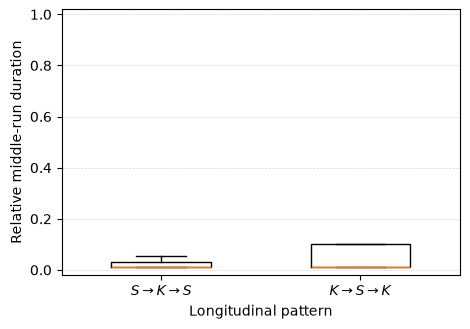

Saved: relative_middle_run_duration.pdf


In [184]:
#mutants = analyze_directory("data_seq")

plot_relative_middle_run_duration(
    mutants,
    out_path="relative_middle_run_duration.pdf",
)